# T03 - Greeks

Nicole Getzabel Flores Godines

22/09/2026

In [25]:
import pandas as pd
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

In [2]:
S = 100

datos = {
    "Opción": ["A", "B", "C"],
    "K": [90, 100, 120],
    "T": [1/12, 3/12, 1],
    "Prima": [12, 8, 5],
    "Delta": [0.85, 0.50, 0.20],
    "Vega": [0.05, 0.25, 0.40],
    "Theta": [-0.10, -0.03, -0.01]
}

opciones = pd.DataFrame(datos)

opciones

,Opción,K,T,Prima,Delta,Vega,Theta
0,A,90,0.083333,12,0.85,0.05,-0.10
1,B,100,0.250000,8,0.50,0.25,-0.03
2,C,120,1.000000,5,0.20,0.40,-0.01


### Parte 1: Observación

 **1. ¿Cuál opción parece más sensible a cambios en el precio de la acción?**

La opción A, porque tiene la Delta más alta (0.85). Esto significa que, si la acción aumenta $1, el valor de la opción subiría aproximadamente $0.85, manteniendo los demás factores constantes.

**2. ¿Cuál opción parece más sensible a cambios en volatilidad?**

La opción C, porque tiene la Vega más alta (0.40). Esto significa que su valor reaccionaría más ante cambios en la volatilidad, suponiendo que las tres opciones utilizan las mismas unidades de medición.

**3. ¿Cuál opción parece deteriorarse más rápidamente con el paso del tiempo?**

La opción A, porque tiene la Theta más negativa (-0.10). Esto indica que pierde valor más rápidamente por el paso del tiempo, si los demás factores permanecen constantes.

**4. ¿Cuál opción parece tener el comportamiento más parecido al de la acción?**

La opción A, porque su Delta de 0.85 es la más cercana a 1. Esto quiere decir que su precio se mueve de manera más parecida al de la acción.

**5. ¿Cuál opción parece depender más de que ocurra un evento importante en el futuro?**

La opción C, porque tiene una Vega alta y un vencimiento de un año. Además, necesita que la acción suba considerablemente para superar su precio de ejercicio de $120. Un evento que aumente la volatilidad o provoque una subida importante podría beneficiarla, aunque no garantiza ganancias.


### Parte 2: Escenarios de mercado

##### Escenario A. La acción aumentará gradualmente y la volatilidad no cambiará.
Compraría la opción B porque tiene tres meses de vencimiento, lo que da tiempo para aprovechar el aumento gradual de la acción. Además, tiene una Delta de 0.50 y pierde menos valor por el paso del tiempo que la opción A, según sus Theta.

Evitaría la opción C porque su precio de ejercicio es de $120 y necesitaría que la acción subiera bastante para obtener ganancias al vencimiento.

##### Escenario B. Se anunciará un producto y se espera un movimiento brusco.
Compraría la opción B porque tiene una Vega de 0.25, por lo que puede beneficiarse si aumenta la volatilidad. Además, su precio de ejercicio es de $100, igual al precio actual de la acción.

Evitaría la opción A porque tiene una Theta más negativa y pierde valor más rápido con el tiempo.

Sin embargo, como no sé si la acción subirá o bajará, existe el riesgo de perder dinero si compro una call y el precio cae.

##### Escenario C. La acción se mantendrá muy estable.
Si la acción se mantiene estable, las opciones pueden perder valor por el paso del tiempo. Evitaría la opción B porque su prima de $8 es completamente valor temporal y podría perderla si la acción permanece en $100 hasta el vencimiento.

Si tuviera que elegir obligatoriamente una, escogería la opción A, ya que tiene $10 de valor intrínseco y solamente $2 de valor temporal.

##### Escenario D. Se espera una caída significativa del precio de la acción.
No compraría ninguna de las tres y evitaría la opción A porque las tres opciones son de compra, por lo que generalmente pierden valor cuando baja el precio de la acción.

Evitaría especialmente la opción A porque tiene la Delta más alta (0.85), lo que significa que es la más sensible a una caída inicial del precio, manteniendo constantes los demás factores.

Si quisiera aprovechar una caída del mercado, consideraría comprar una opción put, ya que esta puede aumentar de valor cuando baja el precio de la acción.

##### Escenario E. El mercado está subestimando la incertidumbre futura.
Compraría la opción C porque tiene la Vega más alta (0.40), por lo que podría beneficiarse más si aumenta la volatilidad implícita.

Evitaría la opción A porque tiene la Vega más baja (0.05), así que su valor es menos sensible a los cambios en la volatilidad.

Mi decisión sería comprar la opción C si espero que la volatilidad implícita aumente, aunque tendría que considerar que también puedo perder la prima si el movimiento esperado no ocurre.

### Parte 3: Simulación

In [4]:
datos = {
    "Mes": ["Mayo", "Junio", "Julio", "Agosto",
            "Septiembre", "Octubre"],
    "Precio": [100, 102, 101, 105, 103, 110],
    "Volatilidad": [0.20, 0.25, 0.30, 0.28, 0.22, 0.20]
}

df = pd.DataFrame(datos)
df

,Mes,Precio,Volatilidad
0,Mayo,100,0.20
1,Junio,102,0.25
2,Julio,101,0.30
3,Agosto,105,0.28
4,Septiembre,103,0.22
5,Octubre,110,0.20


In [5]:
r = 0.05
K = 100
V0 = 6.8887

delta = 0.5977
gamma = 0.02736
vega = 0.2814
theta = -8.116

dt = 1/12

los cambios mensuales

In [13]:
df["dS"] = df["Precio"].diff()

df["dsigma"] = df["Volatilidad"].diff() * 100
df

,Mes,Precio,Volatilidad,dS,dσ,Valor Greeks,Tiempo,dsigma
0,Mayo,100,0.20,NaN,NaN,6.888700,0.500000,NaN
1,Junio,102,0.25,2.0,5.0,8.869487,0.416667,5.0
2,Julio,101,0.30,-1.0,5.0,9.016133,0.333333,5.0
3,Agosto,105,0.28,4.0,-2.0,10.386680,0.250000,-2.0
4,Septiembre,103,0.22,-2.0,-6.0,6.881267,0.166667,-6.0
5,Octubre,110,0.20,7.0,-2.0,10.496353,0.083333,-2.0


Calcular el valor de la opción con Greeks

In [9]:
valores = [V0]

for i in range(1, len(df)):

    dS = df.loc[i, "dS"]
    dsigma = df.loc[i, "dσ"]

    V_anterior = valores[-1]

    V_nuevo = (
        V_anterior
        + delta * dS
        + 0.5 * gamma * dS**2
        + vega * dsigma
        + theta * dt
    )

    valores.append(V_nuevo)

df["Valor Greeks"] = valores
df.round(4)

,Mes,Precio,Volatilidad,dS,dσ,Valor Greeks
0,Mayo,100,0.20,NaN,NaN,6.8887
1,Junio,102,0.25,2.0,5.0,8.8695
2,Julio,101,0.30,-1.0,5.0,9.0161
3,Agosto,105,0.28,4.0,-2.0,10.3867
4,Septiembre,103,0.22,-2.0,-6.0,6.8813
5,Octubre,110,0.20,7.0,-2.0,10.4964


In [10]:
valores = [V0]

for i in range(1, len(df)):

    dS = df.loc[i, "dS"]
    dsigma = df.loc[i, "dσ"]

    V_anterior = valores[-1]

    V_nuevo = (
        V_anterior
        + delta * dS
        + 0.5 * gamma * dS**2
        + vega * dsigma
        + theta * dt
    )

    valores.append(V_nuevo)

df["Valor Greeks"] = valores
df.round(4)

,Mes,Precio,Volatilidad,dS,dσ,Valor Greeks
0,Mayo,100,0.20,NaN,NaN,6.8887
1,Junio,102,0.25,2.0,5.0,8.8695
2,Julio,101,0.30,-1.0,5.0,9.0161
3,Agosto,105,0.28,4.0,-2.0,10.3867
4,Septiembre,103,0.22,-2.0,-6.0,6.8813
5,Octubre,110,0.20,7.0,-2.0,10.4964


simular 10000 escenarios

In [11]:
df["Tiempo"] = [6/12, 5/12, 4/12, 3/12, 2/12, 1/12]
df

,Mes,Precio,Volatilidad,dS,dσ,Valor Greeks,Tiempo
0,Mayo,100,0.20,NaN,NaN,6.888700,0.500000
1,Junio,102,0.25,2.0,5.0,8.869487,0.416667
2,Julio,101,0.30,-1.0,5.0,9.016133,0.333333
3,Agosto,105,0.28,4.0,-2.0,10.386680,0.250000
4,Septiembre,103,0.22,-2.0,-6.0,6.881267,0.166667
5,Octubre,110,0.20,7.0,-2.0,10.496353,0.083333


Calcular Black-Scholes

In [18]:
def black_scholes(S, K, r, sigma, T):

    d1 = (np.log(S/K) + (r + sigma**2/2)*T) / (sigma*np.sqrt(T))

    d2 = d1 - sigma*np.sqrt(T)

    call = S*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)

    return call

df["Black-Scholes"] = df.apply(
    lambda x: black_scholes(
        x["Precio"],
        K,
        r,
        x["Volatilidad"],
        x["Tiempo"]
    ),
    axis=1
)

df[["Mes", "Precio", "Volatilidad", "Tiempo", "Black-Scholes"]].round(4)


,Mes,Precio,Volatilidad,Tiempo,Black-Scholes
0,Mayo,100,0.20,0.5000,6.8887
1,Junio,102,0.25,0.4167,8.6621
2,Julio,101,0.30,0.3333,8.2860
3,Agosto,105,0.28,0.2500,9.3418
4,Septiembre,103,0.22,0.1667,5.8530
5,Octubre,110,0.20,0.0833,10.5202


In [20]:
np.random.seed(2026)

resultados_mc = []

for i in range(len(df)):
    S = df.loc[i, "Precio"]
    sigma = df.loc[i, "Volatilidad"]
    T = df.loc[i, "Tiempo"]
    Z = np.random.normal(0, 1, 10000)
    ST = S * np.exp(
        (r - 0.5*sigma**2)*T
        + sigma*np.sqrt(T)*Z
    )

    payoff = np.maximum(ST - K, 0)
    valor_mc = np.exp(-r*T)*np.mean(payoff)
    resultados_mc.append(valor_mc)

df["Monte Carlo"] = resultados_mc
df[["Mes", "Precio", "Volatilidad",
    "Tiempo", "Black-Scholes", "Monte Carlo"]].round(4)


,Mes,Precio,Volatilidad,Tiempo,Black-Scholes,Monte Carlo
0,Mayo,100,0.20,0.5000,6.8887,7.1422
1,Junio,102,0.25,0.4167,8.6621,8.7257
2,Julio,101,0.30,0.3333,8.2860,8.2641
3,Agosto,105,0.28,0.2500,9.3418,9.3893
4,Septiembre,103,0.22,0.1667,5.8530,5.8122
5,Octubre,110,0.20,0.0833,10.5202,10.5490


In [ ]:
df["Error absoluto"] = abs(
    df["Valor Greeks"] - df["Black-Scholes"]
)

df.loc[0, "Error absoluto"] = np.nan

comparacion = df[[
    "Mes",
    "Valor Greeks",
    "Black-Scholes",
    "Error absoluto"
]].copy()

comparacion.loc[0, "Valor Greeks"] = np.nan

display(comparacion.round(4).fillna("-"))

,Mes,Valor Greeks,Black-Scholes,Error absoluto
0,Mayo,-,6.8887,-
1,Junio,8.8695,8.6621,0.2074
2,Julio,9.0161,8.2860,0.7301
3,Agosto,10.3867,9.3418,1.0449
4,Septiembre,6.8813,5.8530,1.0283
5,Octubre,10.4964,10.5202,0.0239


Graficar Greeks vs. Black-Scholes

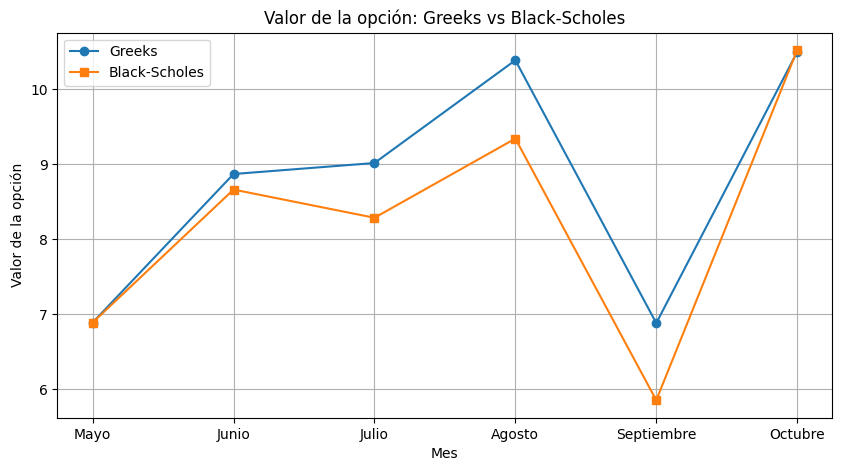

In [28]:
plt.figure(figsize=(10, 5))

plt.plot(
    df["Mes"],
    df["Valor Greeks"],
    marker="o",
    label="Greeks"
)

plt.plot(
    df["Mes"],
    df["Black-Scholes"],
    marker="s",
    label="Black-Scholes"
)

plt.title("Valor de la opción: Greeks vs Black-Scholes")
plt.xlabel("Mes")
plt.ylabel("Valor de la opción")
plt.legend()
plt.grid(True)
plt.show()

### 1. ¿Los Greeks iniciales describen con precisión toda la trayectoria?

No completamente. Los Greeks iniciales sirven para hacer una aproximación, pero conforme cambian el precio de la acción, la volatilidad y el tiempo, también cambian las sensibilidades de la opción. Por eso, al usar los mismos Greeks durante todos los meses, aparecen diferencias con Black-Scholes.

### 2. ¿En qué mes apareció el error más grande?

El error más grande apareció en agosto, con aproximadamente $1.0449 de diferencia entre el valor calculado con Greeks y el valor de Black-Scholes.

### 3. ¿Qué factor parece contribuir más al error?

Pienso que uno de los factores principales es que se utilizaron los mismos Greeks iniciales durante toda la trayectoria. Además, hubo cambios importantes tanto en el precio de la acción como en la volatilidad, por lo que las sensibilidades iniciales ya no representaban exactamente el comportamiento de la opción.

### 4. ¿Por qué los Greeks funcionan mejor para movimientos pequeños que para movimientos grandes?

Porque los Greeks representan cambios aproximados alrededor de una situación inicial. Cuando los movimientos son pequeños, la aproximación es más precisa. En cambio, cuando el precio o la volatilidad cambian mucho, las propias sensibilidades también cambian y el error puede aumentar.

### 5. Si la trayectoria fuera mucho más volátil, ¿esperarías errores menores? ¿Por qué?

No. Esperaría que los errores fueran mayores, porque habría cambios más fuertes en el precio y en la volatilidad. Eso haría que los Greeks iniciales dejaran de representar con precisión la situación del mercado.

### 6. Conclusión

En esta actividad entendí que los Greeks son útiles para conocer cómo puede cambiar el valor de una opción ante movimientos en el precio, la volatilidad y el tiempo. Sin embargo, también aprendí que no es suficiente utilizar siempre los mismos valores iniciales, porque las condiciones del mercado cambian.

Al comparar los resultados con Black-Scholes, observé que la aproximación con Greeks puede funcionar bien para cambios pequeños, pero puede presentar errores cuando los movimientos son más grandes. Por eso, para tomar decisiones financieras es importante analizar las sensibilidades, pero también actualizar los cálculos conforme cambian las condiciones del mercado.